In [1]:
import arviz as az
import bambi as bmb
import polars as  pl
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

from kidney.contrasts import get_t_groups, get_overall_effects, get_gtyp_given_sex_age, get_sex_given_gtyp_age
from kidney.paths import RESULTS_DIR_NEW, PREPARED_FILES_NEW, PLOT_DIR_NEW
from kidney.plotting import forestplot_oz, plot_ppc, set_symmetric_xlim
from kidney.sign_probs import get_sign_probs, get_signif

In [2]:
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'Arial'
az.rcParams["data.load"] = "eager"

In [3]:
idata_vehicle = az.from_netcdf(RESULTS_DIR_NEW / "idata_baseline_power_vehicle_lfb.nc")
idata_empa = az.from_netcdf(RESULTS_DIR_NEW / "idata_baseline_power_empa_lfb.nc")

In [4]:
print("Vehicle:")
display(az.summary(idata_vehicle, var_names=["~mu", "~1|rat", "~sigma"]))
print("Empa:")
display(az.summary(idata_empa, var_names=["~mu", "~1|rat", "~sigma"]))

Vehicle:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,1.022,0.245,0.573,1.495,0.008,0.005,972.0,1493.0,1.0
gtyp[fa/fa],-0.113,0.391,-0.896,0.564,0.011,0.008,1234.0,1571.0,1.0
age[Young],-0.375,0.356,-1.069,0.254,0.011,0.007,1047.0,1825.0,1.0
sex[M],-0.344,0.364,-1.037,0.341,0.011,0.007,1185.0,1502.0,1.0
"gtyp:age[fa/fa, Young]",0.190,0.510,-0.795,1.110,0.016,0.010,1071.0,1893.0,1.0
"gtyp:sex[fa/fa, M]",-0.144,0.505,-1.136,0.805,0.014,0.011,1210.0,1733.0,1.0
1|rat_sigma,0.661,0.110,0.466,0.856,0.004,0.002,902.0,1816.0,1.0


Empa:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.502,0.171,0.189,0.828,0.005,0.003,1026.0,1841.0,1.00
gtyp[fa/fa],0.097,0.264,-0.389,0.609,0.008,0.005,1130.0,1924.0,1.00
age[Young],-0.304,0.246,-0.771,0.163,0.007,0.005,1255.0,1819.0,1.00
sex[M],0.204,0.241,-0.250,0.658,0.008,0.005,934.0,1782.0,1.00
"gtyp:age[fa/fa, Young]",0.616,0.349,-0.041,1.247,0.009,0.007,1344.0,1927.0,1.00
"gtyp:sex[fa/fa, M]",-0.799,0.349,-1.444,-0.114,0.011,0.007,1102.0,1687.0,1.00
1|rat_sigma,0.459,0.076,0.329,0.606,0.002,0.001,1086.0,2374.0,1.01


In [5]:
msts_vehicle = pl.read_csv(PREPARED_FILES_NEW["baseline_power_vehicle_lfb"])
msts_empa = pl.read_csv(PREPARED_FILES_NEW["baseline_power_empa_lfb"])

## Posterior predictive checks

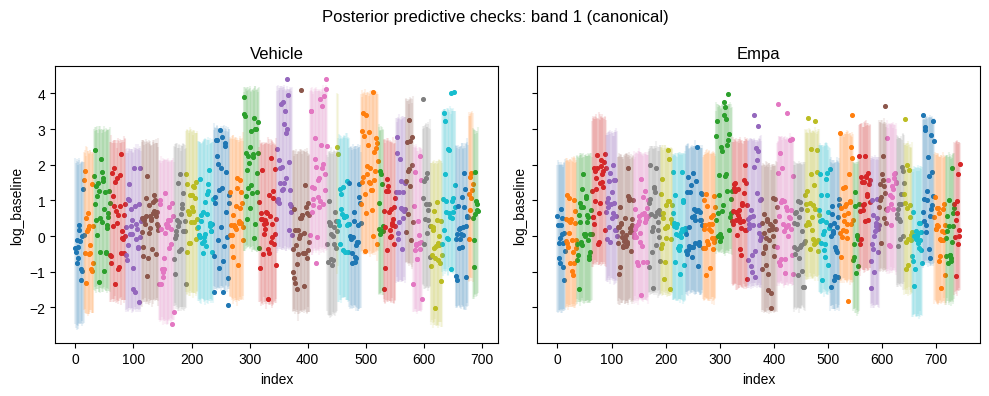

In [6]:
PLOT_DIR_NEW.mkdir(parents=True, exist_ok=True)
f, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, idata, name, msts in zip(
    axes,
    (idata_vehicle, idata_empa),
    ("vehicle", "empa"),
    (msts_vehicle, msts_empa),
):
    ax = plot_ppc(ax, idata, msts, ycol="log_baseline", groupcol="rat")
    ax.set_title(name.capitalize())
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

f.suptitle("Posterior predictive checks: band 1 (canonical)")
f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ppc_baseline_power-lf-band.png", bbox_inches="tight", dpi=200)

Each dot is a vessel, sorted by rat; lines are 1%–99% posterior predictive intervals. The dataset now contains only low-frequency baseline power, so there is no band-specific subdivision.

## Effects

The model is `log_baseline ~ (1|rat) + gtyp + age + sex + gtyp:age + gtyp:sex`, with a single residual standard deviation. Contrasts follow the brief. The overall effect of a factor is averaged with equal weights over the levels of the other factors, e.g. the overall gtyp effect is the mean of fa/fa − fa/+ over the four age/sex groups. The gtyp effect given sex is averaged over age, and vice versa. SP is the posterior probability that the contrast is positive; lines are 95% intervals.
The combined plot replaces the overall sex effect with male − female contrasts within `fa/fa` and `fa/+`, averaged over age. Sex-given-age contrasts are excluded.

In [7]:
def plot_effects(ts_vehicle, ts_empa, figsize):
    f, axes = plt.subplots(1, 2, figsize=figsize)
    for ax, ts, tle in zip(axes, (ts_vehicle, ts_empa), ("Vehicle", "Empa")):
        ax = forestplot_oz(ax, ts, xlabel="Test statistic\n(baseline power)", sign_probs=True)
        set_symmetric_xlim(ax, ts, pad=1.8)
        ax.set_title(tle)
        ax.spines[['top', 'right', 'left']].set_visible(False)
    axes[1].set_yticks([], [])
    return f, axes


t_groups_vehicle, t_groups_empa = (get_t_groups(idata) for idata in (idata_vehicle, idata_empa))
overall_ts_vehicle, overall_ts_empa = (
    get_overall_effects(t_groups)
    for t_groups in (t_groups_vehicle, t_groups_empa)
)
gtyp_ts_vehicle, gtyp_ts_empa = (get_gtyp_given_sex_age(t_groups) for t_groups in (t_groups_vehicle, t_groups_empa))
sex_ts_vehicle, sex_ts_empa = (
    get_sex_given_gtyp_age(t_groups)
    for t_groups in (t_groups_vehicle, t_groups_empa)
)

# Replace the overall sex contrast with sex effects within each genotype.
# Exclude the sex-given-age contrasts.
plot_ts_vehicle = {
    **{k: v for k, v in overall_ts_vehicle.items() if k != "male - female"},
    **{k: v for k, v in sex_ts_vehicle.items() if k in ("male - female, fa/fa", "male - female, fa/+")},
}
plot_ts_empa = {
    **{k: v for k, v in overall_ts_empa.items() if k != "male - female"},
    **{k: v for k, v in sex_ts_empa.items() if k in ("male - female, fa/fa", "male - female, fa/+")},
}

### Overall genotype and age effects; sex effects given genotype

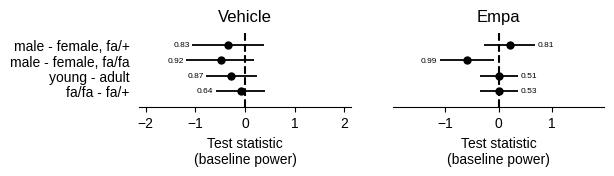

In [8]:
f, axes = plot_effects(plot_ts_vehicle, plot_ts_empa, figsize=(6, 1))
f.savefig(PLOT_DIR_NEW / "ts_baseline_power_overall_and_sg-lf.pdf", bbox_inches="tight", dpi=200)

### Effect of gtyp given sex and given age

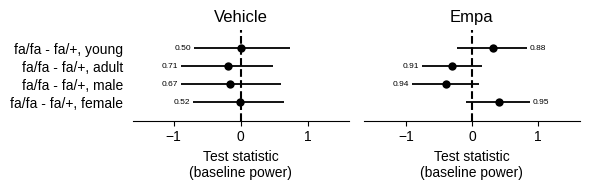

In [9]:
f, axes = plot_effects(gtyp_ts_vehicle, gtyp_ts_empa, figsize=(6, 2))
f.tight_layout()
# f.savefig(PLOT_DIR_NEW / "ts_baseline_power_gtyp_given_sex_age-lf.pdf", bbox_inches="tight", dpi=200)

## Show sign probabilities in tables

In [10]:
sp_all = pd.concat(
    objs=[
        pd.DataFrame({
            "vehicle": get_sign_probs(ts_vehicle),
            "vehicle_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_vehicle).items()},
            "empa": get_sign_probs(ts_empa),
            "empa_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_empa).items()},
        })
        for ts_vehicle, ts_empa in (
            (plot_ts_vehicle, plot_ts_empa),
            (gtyp_ts_vehicle, gtyp_ts_empa),
        )
    ],
    keys=("overall + sex given gtyp", "gtyp given sex/age"),
    names=("contrast", "group"),
)
sp_all

vehicle vehicle_signif  \
contrast                 group                                          
overall + sex given gtyp fa/fa - fa/+          0.64350                  
                         young - adult         0.86625                  
                         male - female, fa/fa  0.91525                  
                         male - female, fa/+   0.83275                  
gtyp given sex/age       fa/fa - fa/+, female  0.52200                  
                         fa/fa - fa/+, male    0.67425                  
                         fa/fa - fa/+, adult   0.70650                  
                         fa/fa - fa/+, young   0.50000                  

                                                  empa empa_signif  
contrast                 group                                      
overall + sex given gtyp fa/fa - fa/+          0.52600              
                         young - adult         0.51025              
                         male - female, fa/fa  0.98850           *  
                         male - female, fa/+   0.81250              
gtyp given sex/age       fa/fa - fa/+, female  0.94925              
                         fa/fa - fa/+, male    0.94000              
                         fa/fa - fa/+, adult   0.90950              
                         fa/fa - fa/+, young   0.88250